Mount Google Drive

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


Imports

In [3]:
import os
import h5py
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from tqdm import tqdm

PATHS

In [4]:
BASE_PATH = Path("/content/drive/MyDrive/fyp")

CHENG_PATH = BASE_PATH / "Data/Cheng Data/data"

NO_TUMOR_PATH = BASE_PATH / "Data/No_tumor/notumor"

OUTPUT_PATH = BASE_PATH / "Processed Dataset"


print(CHENG_PATH)
print(NO_TUMOR_PATH)
print(OUTPUT_PATH)

/content/drive/MyDrive/fyp/Data/Cheng Data/data
/content/drive/MyDrive/fyp/Data/No_tumor/notumor
/content/drive/MyDrive/fyp/Processed Dataset


Create Output Folders

In [5]:
IMAGE_DIR = OUTPUT_PATH / "images" #used for classification

MASK_DIR = OUTPUT_PATH / "masks" #Used for segmentation


IMAGE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MASK_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print("Directories created")

Directories created


Check Data Files

In [6]:
cheng_files = sorted(
    CHENG_PATH.glob("*.mat")
)


no_tumor_files = sorted(
    NO_TUMOR_PATH.glob("*.jpg")
)


print(
    "Cheng files:",
    len(cheng_files)
)


print(
    "No tumor images:",
    len(no_tumor_files)
)

Cheng files: 3064
No tumor images: 1414


Rading .mat(V7.3)Files from Cheng Data

In [7]:
def read_cheng_mat(file_path):

    with h5py.File(file_path, "r") as f:

        cjdata = f["cjdata"]


        image = np.array(
            cjdata["image"]
        )


        mask = np.array(
            cjdata["tumorMask"]
        )


        label = int(
            np.array(
                cjdata["label"]
            )[0][0]
        )


        patient_id = None


        if "PID" in cjdata:

            patient_id = np.array(
                cjdata["PID"]
            )


    return image, mask, label, patient_id

In [8]:
sample_file = cheng_files[0]


img, mask, label, pid = read_cheng_mat(sample_file)


print("Image shape:", img.shape)
print("Mask shape:", mask.shape)
print("Label:", label)
print("Patient ID:", pid)

Image shape: (512, 512)
Mask shape: (512, 512)
Label: 1
Patient ID: [[49]
 [48]
 [48]
 [51]
 [54]
 [48]]


Label Mapping

In [9]:
LABEL_MAP = {

    1:"meningioma",

    2:"glioma",

    3:"pituitary"

}


LABEL_MAP

{1: 'meningioma', 2: 'glioma', 3: 'pituitary'}

Image Norm Function

In [10]:
def normalize_image(img):

    img = img.astype(
        np.float32
    )


    img = (
        (img - img.min()) /
        (img.max() - img.min())
        *255
    )


    return img.astype(
        np.uint8
    )

Processing Cheng Images

In [11]:
metadata = []


counter = 0


for file in tqdm(cheng_files):

    try:

        image, mask, label, pid = read_cheng_mat(file)


        class_name = LABEL_MAP[label]


        image = normalize_image(image)


        mask = (mask > 0).astype(np.uint8)* 255



        image_name = (
            f"cheng_{counter:06d}.png"
        )


        mask_name = (
            f"cheng_{counter:06d}_mask.png"
        )



        Image.fromarray(image).save(IMAGE_DIR/image_name)



        Image.fromarray(mask).save(MASK_DIR/mask_name)



        metadata.append({

            "image": image_name,

            "mask": mask_name,

            "class": class_name,

            "label": label,

            "patient_id": str(pid),

            "source": "cheng",

            "client_id": None

        })


        counter += 1


    except Exception as e:

        print(
            "Failed:",
            file,
            e
        )

100%|██████████| 3064/3064 [05:07<00:00,  9.95it/s]


Empty mask function

In [12]:
def create_empty_mask(shape):

    return np.zeros(
        shape,
        dtype=np.uint8
    )

process no-tumor data

In [13]:
counter = 0


for file in tqdm(no_tumor_files):

    img = Image.open(
        file
    ).convert(
        "L"
    )


    img_array = np.array(
        img
    )


    mask = create_empty_mask(
        img_array.shape
    )


    image_name = (
        f"no_tumor_{counter:06d}.png"
    )


    mask_name = (
        f"no_tumor_{counter:06d}_mask.png"
    )


    Image.fromarray(
        img_array
    ).save(
        IMAGE_DIR / image_name
    )


    Image.fromarray(
        mask
    ).save(
        MASK_DIR / mask_name
    )



    metadata.append({

        "image": image_name,

        "mask": mask_name,

        "class": "no_tumor",

        "label": 0,

        "patient_id": None,

        "source": "kaggle",

        "client_id": None

    })


    counter += 1

100%|██████████| 1414/1414 [07:31<00:00,  3.13it/s]


Save Metadeta

In [14]:
df = pd.DataFrame(
    metadata
)


metadata_path = (
    OUTPUT_PATH /
    "metadata.csv"
)


df.to_csv(
    metadata_path,
    index=False
)


print(
    "Saved:",
    metadata_path
)


df.head()

Saved: /content/drive/MyDrive/fyp/Processed Dataset/metadata.csv


,image,mask,class,label,patient_id,source,client_id
0,cheng_000000.png,cheng_000000_mask.png,meningioma,1,[[49]\n [48]\n [48]\n [51]\n [54]\n [48]],cheng,None
1,cheng_000001.png,cheng_000001_mask.png,meningioma,1,[[49]\n [48]\n [49]\n [48]\n [49]\n [54]],cheng,None
2,cheng_000002.png,cheng_000002_mask.png,meningioma,1,[[49]\n [48]\n [55]\n [52]\n [57]\n [52]],cheng,None
3,cheng_000003.png,cheng_000003_mask.png,pituitary,3,[[49]\n [49]\n [50]\n [54]\n [52]\n [57]],cheng,None
4,cheng_000004.png,cheng_000004_mask.png,pituitary,3,[[49]\n [49]\n [50]\n [54]\n [52]\n [57]],cheng,None


In [17]:
print(
    "Total images:",
    len(df)
)


df["class"].value_counts()

Total images: 4478


,count
class,
glioma,1426
no_tumor,1414
pituitary,930
meningioma,708


In [18]:
sample = df.sample(3)


sample

,image,mask,class,label,patient_id,source,client_id
3730,no_tumor_000666.png,no_tumor_000666_mask.png,no_tumor,0,None,kaggle,None
2304,cheng_002304.png,cheng_002304_mask.png,meningioma,1,[[49]\n [48]\n [54]\n [57]\n [49]\n [52]],cheng,None
1900,cheng_001900.png,cheng_001900_mask.png,glioma,2,[[77]\n [82]\n [48]\n [51]\n [55]\n [52]\n [53...,cheng,None


Visual verification

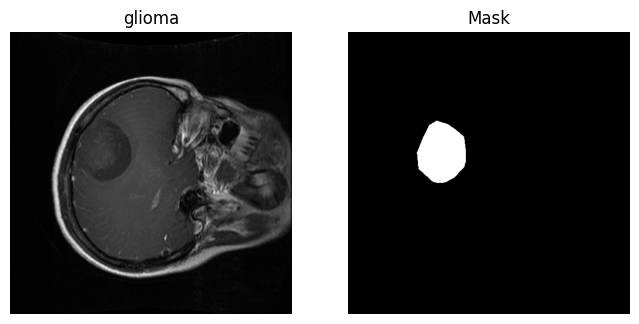

In [20]:

row = df.sample(1).iloc[0]


img = Image.open(
    IMAGE_DIR / row["image"]
)


mask = Image.open(
    MASK_DIR / row["mask"]
)



plt.figure(figsize=(8,4))


plt.subplot(1,2,1)
plt.imshow(img,cmap="gray")
plt.title(row["class"])
plt.axis("off")


plt.subplot(1,2,2)
plt.imshow(mask,cmap="gray")
plt.title("Mask")
plt.axis("off")


plt.show()